In [43]:
import pandas as pd
import numpy as np
import pandahouse
import seaborn as sns
import matplotlib.pyplot as plt
from causalimpact import CausalImpact

In [ ]:
# Команда маркетологов решила организовать флэшмоб в ленте новостей: участники должны сделать пост, 
# где они рассказывают какой-то интересный факт о себе, и опубликовать его с хэштегом. Три поста, 
# собравших наибольшее число лайков, получают призы.

# Флэшмоб проходил с 2026-10-16 по 2026-10-22. Ваша задача как аналитика – оценить эффективность этого мероприятия.

In [ ]:
# подключение к Clickhouse
connection = {
    'host': 'http://clickhouse.lab.karpov.courses:8123',
    'password': '',
    'user': 'student',
    'database': 'simulator_20261020'
}

In [45]:
# данные до и вовремя проведения флешмоба
q = """
WITH post_dates AS (
    SELECT
        post_id,
        toDate(MIN(time)) AS date
    FROM {db}.feed_actions
    GROUP BY post_id
),
daily_new_posts AS (
    SELECT
        COUNT(post_id) as number_of_posts,
        date
    FROM post_dates
    WHERE date <= '2026-10-22'
    GROUP BY date
)
SELECT 
    toDate(fa.time) AS dt, 
    COUNT(DISTINCT user_id) AS dau,
    SUM(action = 'like') / SUM(action = 'view') AS ctr,
    SUM(action = 'view') AS views,
    number_of_posts AS new_posts,
    COUNT(DISTINCT fa.post_id) FILTER(WHERE action = 'view') AS unique_viewed_posts
FROM {db}.feed_actions fa
    LEFT JOIN daily_new_posts dnp ON dnp.date = toDate(fa.time)
WHERE toDate(fa.time) <= '2026-10-22'
GROUP BY dt, number_of_posts
ORDER BY dt
"""

daily_metrics = pandahouse.read_clickhouse(q, connection=connection)

daily_metrics.head()

,dt,dau,ctr,views,new_posts,unique_viewed_posts
0,2026-09-05,878,0.205182,7603,89,89
1,2026-09-06,2238,0.204174,62770,97,178
2,2026-09-07,3105,0.198605,105526,61,191
3,2026-09-08,3721,0.200007,118996,87,211
4,2026-09-09,4617,0.197783,174454,70,214


In [46]:
daily_metrics.describe()

,dt,dau,ctr,views,new_posts,unique_viewed_posts
count,48,48.000000,48.000000,4.800000e+01,48.000000,48.000000
mean,2026-09-28 12:00:00,11271.979167,0.208090,4.553089e+05,73.083333,209.000000
min,2026-09-05 00:00:00,878.000000,0.195531,7.603000e+03,49.000000,89.000000
25%,2026-09-16 18:00:00,8622.500000,0.203368,2.995270e+05,60.000000,187.000000
50%,2026-09-28 12:00:00,12549.000000,0.208224,4.018595e+05,72.000000,202.000000
75%,2026-10-10 06:00:00,14638.250000,0.212051,5.172595e+05,83.000000,227.000000
max,2026-10-22 00:00:00,17452.000000,0.222221,1.224097e+06,105.000000,319.000000
std,NaN,4336.677297,0.006360,2.808329e+05,15.200551,38.679259


In [47]:
# делаем из даты индекс датафрейма 
daily_metrics = daily_metrics.set_index(['dt'])
daily_metrics.index = pd.to_datetime(daily_metrics.index)

daily_metrics.head()

,dau,ctr,views,new_posts,unique_viewed_posts
dt,,,,,
2026-09-05,878,0.205182,7603,89,89
2026-09-06,2238,0.204174,62770,97,178
2026-09-07,3105,0.198605,105526,61,191
2026-09-08,3721,0.200007,118996,87,211
2026-09-09,4617,0.197783,174454,70,214


In [48]:
# устанавливаем даты пре-периода и пост-периода
pre_period_date = [pd.to_datetime('2026-09-05'), pd.to_datetime('2026-10-15')]
post_period_date = [pd.to_datetime('2026-10-16'), pd.to_datetime('2026-10-22')]

In [49]:
# задаем частоту временного ряда
daily_metrics = daily_metrics.asfreq('D')

In [50]:
# применяем CausalImpact для оценки влияния флешмоба на DAU
impact_dau = CausalImpact(data=daily_metrics['dau'],
                          pre_period=pre_period_date,
                          post_period=post_period_date)

2026-11-13 19:52:19.943302: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma/sample/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:52:19.958339: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma/sample_1/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:52:20.313465: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma_CONSTRUCTED_AT_joint_log_prob/sample/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:

2026-11-13 19:52:32.070297: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'AdditiveStateSpaceModel/sample/AdditiveStateSpaceModel/sample_n_joint/scan/while/strided_slice/AdditiveStateSpaceModel/sample/AdditiveStateSpaceModel/sample_n_joint/concat_1' with dtype int32 and shape [2]
	 [[{{node AdditiveStateSpaceModel/sample/AdditiveStateSpaceModel/sample_n_joint/scan/while/strided_slice/AdditiveStateSpaceModel/sample/AdditiveStateSpaceModel/sample_n_joint/concat_1}}]]
2026-11-13 19:52:32.133518: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'AdditiveStateSpaceModel/sample/AdditiveStateSpaceModel/sample_n_joint/scan/whil

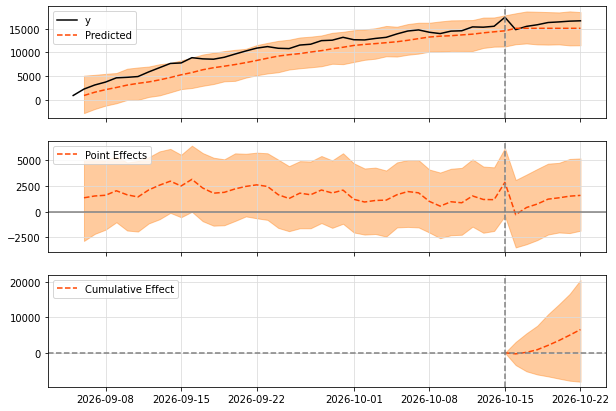

In [51]:
impact_dau.plot()

In [52]:
print(impact_dau.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    16052.71           112369.0
Prediction (s.d.)         15112.76 (984.83)  105789.32 (6893.79)
95% CI                    [13192.7, 17053.15][92348.91, 119372.07]

Absolute effect (s.d.)    939.95 (984.83)    6579.68 (6893.79)
95% CI                    [-1000.44, 2860.01][-7003.07, 20020.09]

Relative effect (s.d.)    6.22% (6.52%)      6.22% (6.52%)
95% CI                    [-6.62%, 18.92%]   [-6.62%, 18.92%]

Posterior tail-area probability p: 0.18
Posterior prob. of a causal effect: 81.52%

For more details run the command: print(impact.summary('report'))


In [53]:
print(impact_dau.summary('report'))

Analysis report {CausalImpact}


During the post-intervention period, the response variable had
an average value of approx. 16052.71. In the absence of an
intervention, we would have expected an average response of 15112.76.
The 95% interval of this counterfactual prediction is [13192.7, 17053.15].
Subtracting this prediction from the observed response yields
an estimate of the causal effect the intervention had on the
response variable. This effect is 939.95 with a 95% interval of
[-1000.44, 2860.01]. For a discussion of the significance of this effect,
see below.


Summing up the individual data points during the post-intervention
period (which can only sometimes be meaningfully interpreted), the
response variable had an overall value of 112369.0.
Had the intervention not taken place, we would have expected
a sum of 105789.32. The 95% interval of this prediction is [92348.91, 119372.07].


The above results are given in terms of absolute numbers. In relative
terms, the response varia

In [54]:
# применяем CausalImpact для оценки влияния флешмоба на CTR
impact_ctr = CausalImpact(data=daily_metrics['ctr'],
                          pre_period=pre_period_date,
                          post_period=post_period_date)

2026-11-13 19:52:36.306256: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma/sample/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:52:36.323491: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma/sample_1/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:52:36.677356: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma_CONSTRUCTED_AT_joint_log_prob/sample/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:

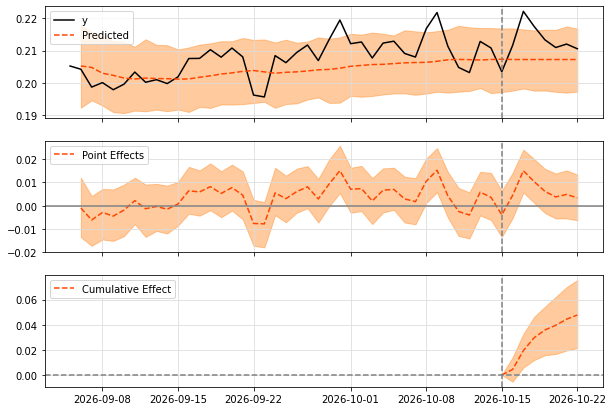

In [55]:
impact_ctr.plot()

In [56]:
print(impact_ctr.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    0.21               1.5
Prediction (s.d.)         0.21 (0.0)         1.45 (0.01)
95% CI                    [0.2, 0.21]        [1.42, 1.48]

Absolute effect (s.d.)    0.01 (0.0)         0.05 (0.01)
95% CI                    [0.0, 0.01]        [0.02, 0.07]

Relative effect (s.d.)    3.29% (0.94%)      3.29% (0.94%)
95% CI                    [1.39%, 5.09%]     [1.39%, 5.09%]

Posterior tail-area probability p: 0.0
Posterior prob. of a causal effect: 100.0%

For more details run the command: print(impact.summary('report'))


In [57]:
print(impact_ctr.summary('report'))

Analysis report {CausalImpact}


During the post-intervention period, the response variable had
an average value of approx. 0.21. By contrast, in the absence of an
intervention, we would have expected an average response of 0.21.
The 95% interval of this counterfactual prediction is [0.2, 0.21].
Subtracting this prediction from the observed response yields
an estimate of the causal effect the intervention had on the
response variable. This effect is 0.01 with a 95% interval of
[0.0, 0.01]. For a discussion of the significance of this effect,
see below.


Summing up the individual data points during the post-intervention
period (which can only sometimes be meaningfully interpreted), the
response variable had an overall value of 1.5.
By contrast, had the intervention not taken place, we would have expected
a sum of 1.45. The 95% interval of this prediction is [1.42, 1.48].


The above results are given in terms of absolute numbers. In relative
terms, the response variable showed an incre

In [58]:
# применяем CausalImpact для оценки влияния флешмоба на число просмотров
impact_views = CausalImpact(data=daily_metrics['views'],
                            pre_period=pre_period_date,
                            post_period=post_period_date)

2026-11-13 19:52:55.522388: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma/sample/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:52:55.537553: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma/sample_1/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:52:55.916366: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma_CONSTRUCTED_AT_joint_log_prob/sample/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:

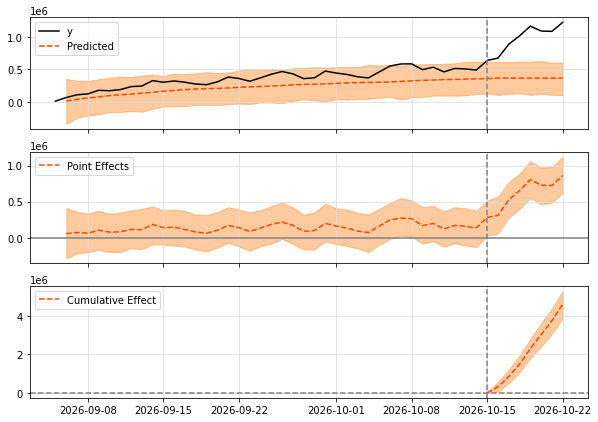

In [59]:
impact_views.plot()

In [60]:
print(impact_views.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    1019947.31         7139631.0
Prediction (s.d.)         363103.22 (49949.4)2541722.5 (349645.82)
95% CI                    [261960.41, 457758.5][1833722.8, 3204309.51]

Absolute effect (s.d.)    656844.12 (49949.4)4597908.5 (349645.82)
95% CI                    [562188.81, 757986.91][3935321.49, 5305908.2]

Relative effect (s.d.)    180.9% (13.76%)    180.9% (13.76%)
95% CI                    [154.83%, 208.75%] [154.83%, 208.75%]

Posterior tail-area probability p: 0.0
Posterior prob. of a causal effect: 100.0%

For more details run the command: print(impact.summary('report'))


In [61]:
print(impact_views.summary('report'))

Analysis report {CausalImpact}


During the post-intervention period, the response variable had
an average value of approx. 1019947.31. By contrast, in the absence of an
intervention, we would have expected an average response of 363103.22.
The 95% interval of this counterfactual prediction is [261960.41, 457758.5].
Subtracting this prediction from the observed response yields
an estimate of the causal effect the intervention had on the
response variable. This effect is 656844.12 with a 95% interval of
[562188.81, 757986.91]. For a discussion of the significance of this effect,
see below.


Summing up the individual data points during the post-intervention
period (which can only sometimes be meaningfully interpreted), the
response variable had an overall value of 7139631.0.
By contrast, had the intervention not taken place, we would have expected
a sum of 2541722.5. The 95% interval of this prediction is [1833722.8, 3204309.51].


The above results are given in terms of absolute number

In [62]:
# применяем CausalImpact для оценки влияния флешмоба на новые посты
impact_new_posts = CausalImpact(data=daily_metrics['new_posts'],
                                pre_period=pre_period_date,
                                post_period=post_period_date)

2026-11-13 19:53:10.837166: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma/sample/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:53:10.853365: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma/sample_1/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:53:11.198723: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma_CONSTRUCTED_AT_joint_log_prob/sample/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:

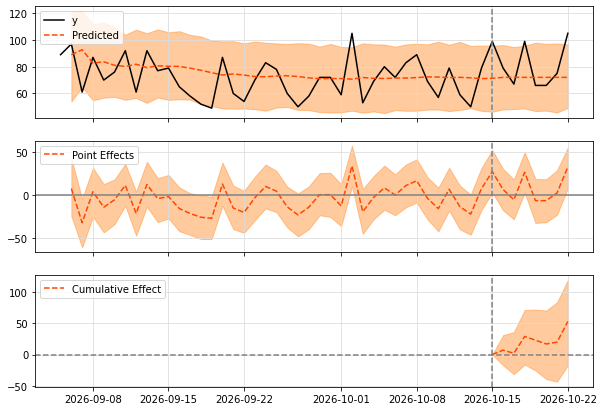

In [63]:
impact_new_posts.plot()

In [64]:
print(impact_new_posts.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    79.57              557.0
Prediction (s.d.)         72.03 (4.88)       504.21 (34.16)
95% CI                    [62.1, 81.23]      [434.71, 568.61]

Absolute effect (s.d.)    7.54 (4.88)        52.79 (34.16)
95% CI                    [-1.66, 17.47]     [-11.61, 122.29]

Relative effect (s.d.)    10.47% (6.77%)     10.47% (6.77%)
95% CI                    [-2.3%, 24.25%]    [-2.3%, 24.25%]

Posterior tail-area probability p: 0.05
Posterior prob. of a causal effect: 94.81%

For more details run the command: print(impact.summary('report'))


In [65]:
print(impact_new_posts.summary('report'))

Analysis report {CausalImpact}


During the post-intervention period, the response variable had
an average value of approx. 79.57. In the absence of an
intervention, we would have expected an average response of 72.03.
The 95% interval of this counterfactual prediction is [62.1, 81.23].
Subtracting this prediction from the observed response yields
an estimate of the causal effect the intervention had on the
response variable. This effect is 7.54 with a 95% interval of
[-1.66, 17.47]. For a discussion of the significance of this effect,
see below.


Summing up the individual data points during the post-intervention
period (which can only sometimes be meaningfully interpreted), the
response variable had an overall value of 557.0.
Had the intervention not taken place, we would have expected
a sum of 504.21. The 95% interval of this prediction is [434.71, 568.61].


The above results are given in terms of absolute numbers. In relative
terms, the response variable showed an increase of +10.

In [66]:
# применяем CausalImpact для оценки влияния флешмоба на уникальные просматриваемые посты
impact_unique_viewed_posts = CausalImpact(data=daily_metrics['unique_viewed_posts'],
                                          pre_period=pre_period_date,
                                          post_period=post_period_date)

2026-11-13 19:53:28.966985: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma/sample/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:53:28.982767: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma/sample_1/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:53:29.361084: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INTERNAL: No function library is provided.
	 [[{{node powerInverseGamma_CONSTRUCTED_AT_joint_log_prob/sample/InverseGamma/sample/PartitionedCall}}]]
2026-11-13 19:

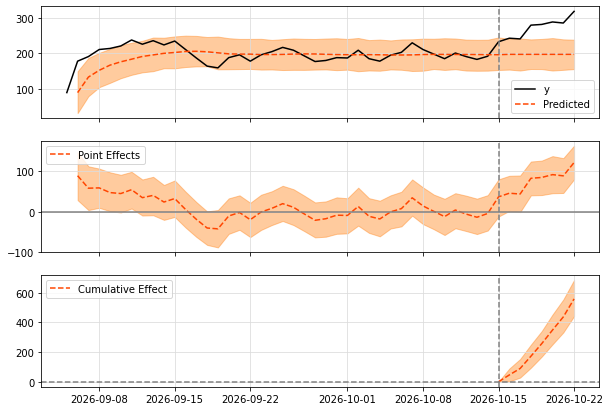

In [67]:
impact_unique_viewed_posts.plot()

In [68]:
print(impact_unique_viewed_posts.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    277.14             1940.0
Prediction (s.d.)         197.33 (8.55)      1381.29 (59.84)
95% CI                    [180.52, 214.03]   [1263.66, 1498.22]

Absolute effect (s.d.)    79.82 (8.55)       558.71 (59.84)
95% CI                    [63.11, 96.62]     [441.78, 676.34]

Relative effect (s.d.)    40.45% (4.33%)     40.45% (4.33%)
95% CI                    [31.98%, 48.96%]   [31.98%, 48.96%]

Posterior tail-area probability p: 0.0
Posterior prob. of a causal effect: 100.0%

For more details run the command: print(impact.summary('report'))


In [69]:
print(impact_unique_viewed_posts.summary('report'))

Analysis report {CausalImpact}


During the post-intervention period, the response variable had
an average value of approx. 277.14. By contrast, in the absence of an
intervention, we would have expected an average response of 197.33.
The 95% interval of this counterfactual prediction is [180.52, 214.03].
Subtracting this prediction from the observed response yields
an estimate of the causal effect the intervention had on the
response variable. This effect is 79.82 with a 95% interval of
[63.11, 96.62]. For a discussion of the significance of this effect,
see below.


Summing up the individual data points during the post-intervention
period (which can only sometimes be meaningfully interpreted), the
response variable had an overall value of 1940.0.
By contrast, had the intervention not taken place, we would have expected
a sum of 1381.29. The 95% interval of this prediction is [1263.66, 1498.22].


The above results are given in terms of absolute numbers. In relative
terms, the response